Inception V3 transfer learning in keras

In [1]:
!pip install split-folders -q

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.applications.inception_v3 import InceptionV3, preprocess_input
from keras.layers import Dense, GlobalAveragePooling2D
from keras.models import Model
from keras.optimizers import Adam

In [3]:
# Download and unziping dataset
!wget https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz
!mkdir -p ./flower_dataset
!tar -xvzf flower_photos.tgz -C ./flower_dataset

--2026-09-27 12:41:39--  https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz
Resolving storage.googleapis.com (storage.googleapis.com)... 142.250.107.207, 192.178.163.207, 173.194.202.207, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|142.250.107.207|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 228813984 (218M) [application/x-compressed-tar]
Saving to: ‘flower_photos.tgz’

flower_photos.tgz   100%[===================>] 218.21M   185MB/s    in 1.2s    

2026-09-27 12:41:41 (185 MB/s) - ‘flower_photos.tgz’ saved [228813984/228813984]

flower_photos/
flower_photos/roses/
flower_photos/roses/14810868100_87eb739f26_m.jpg
flower_photos/roses/1446090416_f0cad5fde4.jpg
flower_photos/roses/15319767030_e6c5602a77_m.jpg
flower_photos/roses/15032112248_30c5284e54_n.jpg
flower_photos/roses/7211616670_2d49ecb3a5_m.jpg
flower_photos/roses/15674450867_0ced942941_n.jpg
flower_photos/roses/17158274118_00ec99a23c.jpg
flo

In [4]:
# !rm -rf 'flower_dataset'  #to delete a non empty floder

In [5]:
# split folder
import splitfolders
splitfolders.ratio('flower_dataset/flower_photos', output='flowers_split', seed=42, ratio=[.7, .2, .1])

Copying files: 3670 files [00:01, 2180.66 files/s]


In [6]:
# from google.colab import files
# import shutil

# # Compress the folder into daisy.zip
# shutil.make_archive('daisy', 'zip', '/content/flower_dataset/flower_photos/tulips')

# # Trigger the download to your device
# files.download('daisy.zip')  -->> download to device

In [8]:
IMG_SIZE=( 299, 299)
BATCH_SIZE= 64
train_datagen=ImageDataGenerator(preprocessing_function=preprocess_input,
                                 rotation_range= 30, zoom_range=0.2,
                                 horizontal_flip=True)
val_datagen=ImageDataGenerator(preprocessing_function=preprocess_input)
test_datagen=ImageDataGenerator(preprocessing_function=preprocess_input)

train_gen=train_datagen.flow_from_directory(
    'flowers_split/train', target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical'
)
val_gen=val_datagen.flow_from_directory(
    'flowers_split/val', target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical'
)
test_gen=test_datagen.flow_from_directory(
    'flowers_split/test', target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical'
)

Found 2567 images belonging to 5 classes.
Found 731 images belonging to 5 classes.
Found 372 images belonging to 5 classes.


In [14]:
# load inception v3 and custom layers
base_model= InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3))
for layer in base_model.layers:
    layer.trainable= False
x=base_model.output
x=GlobalAveragePooling2D()(x)
x=Dense(1024, activation='relu')(x)
predictions= Dense(train_gen.num_classes, activation='softmax')(x)


In [15]:
model= Model(inputs= base_model.input, outputs= predictions)
model.compile(optimizer=Adam(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 299, 299,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_188 (Conv2D) │ (None, 149, 149,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 149, 149,  │         96 │ conv2d_188[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_188      │ (None, 149, 149,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_189 (Conv2D) │ (None, 147, 147,  │      9,216 │ activation_188[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │         96 │ conv2d_189[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_189      │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_190 (Conv2D) │ (None, 147, 147,  │     18,432 │ activation_189[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │        192 │ conv2d_190[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_190      │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 73, 73,    │          0 │ activation_190[0… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_191 (Conv2D) │ (None, 73, 73,    │      5,120 │ max_pooling2d_8[… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 73, 73,    │        240 │ conv2d_191[0][0]  │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_191      │ (None, 73, 73,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_192 (Conv2D) │ (None, 71, 71,    │    138,240 │ activation_191[0… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 71, 71,    │        576 │ conv2d_192[0][0]  │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_192      │ (None, 71, 71,    │          0 │ batch_normalizat

 Total params: 23,906,085 (91.19 MB)

 Trainable params: 2,103,301 (8.02 MB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [16]:
history= model.fit(train_gen, epochs=10, verbose=1, validation_data=val_gen)

Epoch 1/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 151s 3s/step - accuracy: 0.7071 - loss: 0.8305 - val_accuracy: 0.7798 - val_loss: 0.5870
Epoch 2/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step - accuracy: 0.8500 - loss: 0.4514 - val_accuracy: 0.8728 - val_loss: 0.4045
Epoch 3/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.8742 - loss: 0.3708 - val_accuracy: 0.8673 - val_loss: 0.3651
Epoch 4/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - accuracy: 0.8831 - loss: 0.3368 - val_accuracy: 0.8769 - val_loss: 0.3425
Epoch 5/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 67s 2s/step - accuracy: 0.9022 - loss: 0.2890 - val_accuracy: 0.8714 - val_loss: 0.3587
Epoch 6/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 64s 2s/step - accuracy: 0.9135 - loss: 0.2591 - val_accuracy: 0.8769 - val_loss: 0.3200
Epoch 7/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - accuracy: 0.9248 - loss: 0.2371 - val_accuracy: 0.8865 - val_loss: 0.3223
Epoch 8/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 66s 2s/step - accuracy: 0.9264 - loss: 0.2226 - val_accuracy: 0.8974 - val_loss

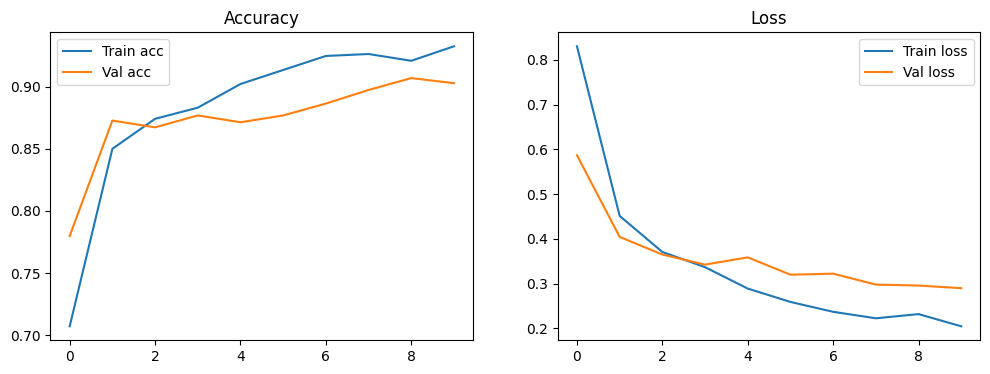

In [17]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.legend()
plt.title('Loss')
plt.show()


In [18]:
loss, acc= model.evaluate(test_gen)
print(f"Test accuracy: {acc:.2f}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 15s 3s/step - accuracy: 0.8952 - loss: 0.3115
Test accuracy: 0.90


In [25]:
from tensorflow.keras.preprocessing import image

def predict_image(img_path):
    img = image.load_img(img_path, target_size=IMG_SIZE)
    img_array = image.img_to_array(img)
    img_array = preprocess_input(img_array)
    img_array = np.expand_dims(img_array, axis=0)
    preds = model.predict(img_array)
    class_index = np.argmax(preds)
    class_label = list(train_gen.class_indices.keys())[class_index]
    print(f"Prediction: {class_label} ({preds[0][class_index]*100:.2f}%)")
    #img.show() # This is for PIL Image objects, not needed for matplotlib
    plt.imshow(img) # Use the loaded image for visualization
    plt.axis('off') # Hide axes
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
Prediction: daisy (86.70%)


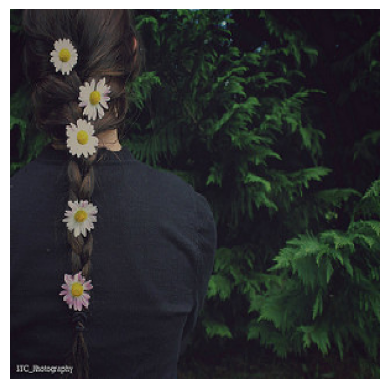

In [26]:
predict_image('/content/flower_dataset/flower_photos/daisy/10172636503_21bededa75_n.jpg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
Prediction: dandelion (99.95%)


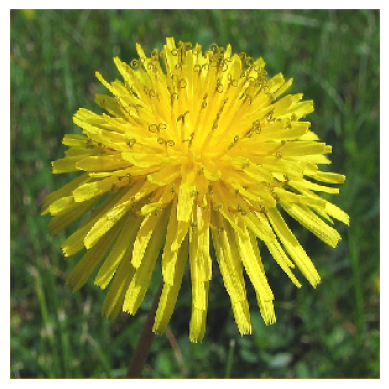

In [35]:
predict_image('/content/flower_dataset/flower_photos/dandelion/1195255751_d58b3d3076.jpg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
Prediction: roses (99.20%)


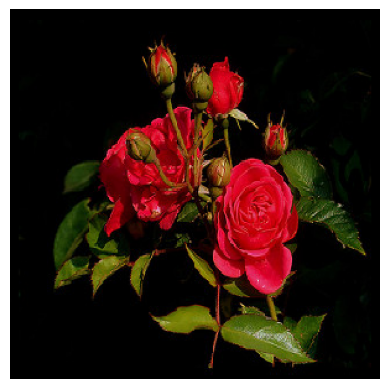

In [43]:
predict_image('/content/flower_dataset/flower_photos/roses/2065522422_cfdd80044a_n.jpg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
Prediction: sunflowers (99.92%)


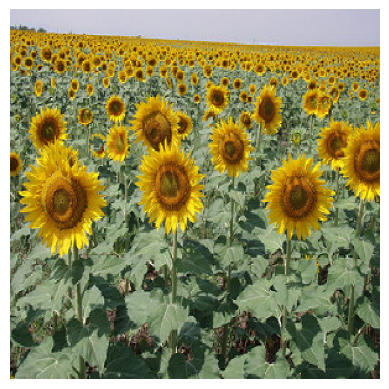

In [44]:
predict_image('/content/flower_dataset/flower_photos/sunflowers/1022552036_67d33d5bd8_n.jpg')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
Prediction: tulips (93.12%)


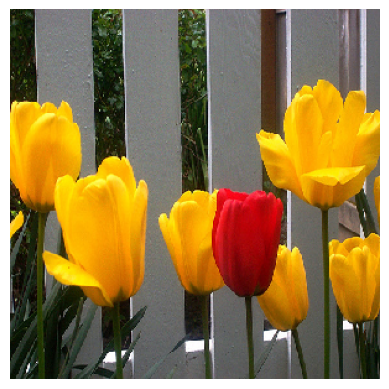

In [45]:
predict_image('/content/flower_dataset/flower_photos/tulips/1353748522_b9c630b162.jpg')